# Effectiveness of thrombolysis in early (4hr) arrivals of mild stroke - good outcome: Causal Forest

## Selection criteria

* Arrival within 4 hours of known stroke onset time
* No thrombectomy
* Stroke type = infarction
* No recorded use of perfusion imaging
* Stroke severity (NIHSS) 1–5

## Outcome

* Good outcome: discharge mRS 0–2, **or** discharge mRS no worse than pre-stroke mRS

## Treatment

* Onset-to-thrombolysis time, grouped as < 180, 180–270 and 270–360 minutes, compared with no thrombolysis

## Adjustment features

* Pre-stroke disability (mRS), stroke severity (NIHSS), age
* Congestive heart failure, hypertension, diabetes
* Atrial fibrillation anticoagulant, any atrial fibrillation diagnosis
* Ethnicity, stroke team

To estimate how the effect of thrombolysis varied between patients, we used a causal forest estimated within a double machine learning framework (CausalForestDML, EconML). In clinical terms, the method asks: for patients who look alike, did those who received thrombolysis do better than we would have expected them to? It works in two stages.

In the first stage, two prediction models were built with gradient-boosted decision trees (LightGBM). The first predicted each patient's probability of a good outcome (mRS 0–2 or no worse than pre-stroke) from their baseline characteristics and stroke team, without knowing the treatment given. These characteristics were age, stroke severity, pre-stroke disability, comorbidities, atrial fibrillation and anticoagulation status, and ethnicity. The second predicted the probability of each treatment category from the same information: no thrombolysis, or thrombolysis within <180, 180–270 or 270–360 minutes of onset. It therefore captures the clinical and organisational factors that influence who is treated.

The models used five-fold cross-fitting, so each patient's predictions came from models trained on other patients. Subtracting the predictions from what actually happened left two residuals: how much better or worse each patient's outcome was than expected, and how far their treatment differed from what would typically be given to someone like them. Removing the predictable part of both treatment and outcome adjusts for measured confounding, including confounding by indication. A further advantage is that small errors in either prediction model have only a limited, second-order effect on the final estimates.

In the second stage, a forest of 2,000 "honest" trees related the outcome residuals to the treatment residuals. Each tree used one half of its data to choose how to split patients into subgroups and the other half to estimate the treatment effect within them, which reduces overfitting. The result was an estimated absolute change in the probability of a good outcome for each patient under each treatment window compared with no thrombolysis. These estimates were then summarised by treatment window and by patient characteristics.

As with any observational analysis, the estimates assume there is no important unmeasured confounding, and that comparable patients were found in both the treated and untreated groups.

![](./images/dml_causal_forest_thrombolysis_method.png)

## Overview

### What this notebook estimates

For each onset-to-thrombolysis window, and for all thrombolysed patients combined, compared with no thrombolysis:

| Estimate | Meaning | How it is calculated |
|---|---|---|
| **ATT** (main result) | Average effect in the patients who were actually thrombolysed in that window | Doubly robust (augmented inverse-probability-weighted, AIPW) estimate from the cross-fitted first-stage models and the forest, with 95% CI |
| **ATT by NIHSS** | The same, within each NIHSS score | AIPW within each NIHSS score, so directly comparable with the matched target trial emulation by NIHSS |
| **ATE** | Average effect if *everyone* in the cohort were thrombolysed in that window | AIPW over all patients; only reported where positivity holds for most of the cohort |
| **Mean CATE in treated** | Simple average of the forest's individual-level estimates | Plug-in average (no CI) |

### Changes from the earlier version of this notebook

* **Categorical features are now passed to LightGBM correctly.** EconML gives the first-stage models the combined matrix `[X, W]`, but the categorical column indices were calculated for `X` and `W` separately. As a result, stroke team was treated as a numeric code and a copy of pre-stroke mRS as categorical. The effect of this fix is shown as a sensitivity analysis.
* **Confidence intervals are now valid.** The earlier tables and charts used mean ± 1.96 × SD / √n of the individual CATE estimates. That SD measures how much the estimates *vary between patients*, not how uncertain the average is, so those intervals were far too narrow. The same problem affected the significance stars in the subgroup charts.
* **The ANOVA test of heterogeneity is replaced.** It treated the forest's predictions for 12,904 patients as independent observations. They are not: they come from the same trees and are strongly correlated, so its P values were not meaningful. Subgroup effects are now doubly robust ATTs with valid CIs, and differences between subgroups are tested with a chi-square test of homogeneity.
* **New checks:**
  * first-stage model performance and overlap
  * comparison with the matched target trial emulation by NIHSS
  * sensitivity analyses and E-values
* **Code tidied:** functions are shared by the primary and sensitivity analyses, and unused imports and code are removed.

### Notebook structure

1. Settings and features
2. Cohort selection and descriptive statistics
3. Model definition and fitting
4. Model diagnostics: first-stage performance and overlap
5. Treatment effects (ATT, ATE, mean CATE)
6. Effects by NIHSS, and comparison with the matched target trial emulation
7. Effects in subgroups of patients treated within 270 minutes
8. Sensitivity analyses
9. Conclusions and limitations

### Key findings

## Key findings

* **Cohort:** 58,389 patients with mild stroke (NIHSS 1–5) arriving within 4 hours. 13,380 (23%) were thrombolysed: 7,390 within 180 min, 5,514 at 180–270 min and 476 at 270–360 min.
* **Overall effect:** In patients who were thrombolysed, thrombolysis increased the probability of a good outcome by **5.0 percentage points (95% CI 4.0 to 6.0)**.
* **Timing:** The benefit was larger when treatment was earlier:
  * **6.3** (5.1 to 7.6) within 180 min
  * **3.5** (2.1 to 4.8) at 180–270 min
  * **1.8** (−2.1 to 5.6) at 270–360 min, which is uncertain
* **Stroke severity:** The effect depended strongly on NIHSS (heterogeneity p < 0.001):
  * **NIHSS 3–5:** clear benefit (5.3, 5.9 and 7.1 points)
  * **NIHSS 1–2:** no detectable benefit (−2.1 and 0.2 points, both CIs including zero)
* **Agreement with the matched target trial emulation:** All estimates were within 2 points of the TTE. The causal forest was slightly lower overall (5.0 vs 5.7).
* **Robustness:** Results were stable across model settings, cohort definitions and seeds (overall 5.0–5.4).
* **What changed the results:**
  * Adding onset-to-scan time and year reduced the overall effect to 3.4 points (<180 min: 3.7).
  * Using an excellent outcome (mRS 0–1) increased it to 6.2–6.6 points.
* **Unmeasured confounding:** E-values are modest (overall 1.34; CI limit 1.29). The results could be explained by an unmeasured confounder that is moderately associated with both thrombolysis and outcome, such as rapidly improving symptoms.

## Load modules

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from econml.dml import CausalForestDML  # causal forest within double machine learning
from lightgbm import LGBMClassifier
from scipy import stats
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")

## Settings

All analysis choices are set here. The sensitivity analyses change one at a time.

In [2]:
prefix = "mild_stroke_early_arrival_good_outcome_causal_forest"
DATA_PATH = "../data/sam3/cleaned_data_anon_teams.csv"
OUTPUT_DIR = "./output"
TTE_SUMMARY_PATH = ("../4_target_trial_emulation/output/"
                    "mild_stroke_by_nihss_1_to_5_early_arrival_good_outcome_target_trial_summary_full.csv")

MRS_TARGET = 2                 # good outcome: discharge mRS <= MRS_TARGET, or no worse than pre-stroke mRS

# Cohort
NIHSS_VALUES = [1, 2, 3, 4, 5]
MAX_ARRIVAL = 240              # include patients arriving within this many minutes of onset
MAX_THROMBOLYSIS = 360         # exclude thrombolysis later than this
MIN_TEAM_THROMBOLYSIS = 10     # include teams that gave at least this many thrombolyses in the cohort
NO_TREATMENT = 99999           # sentinel time meaning "not thrombolysed"
TIME_THROMBOLYSIS = "onset_to_thrombolysis_time"

# First-stage (nuisance) models: LightGBM gradient-boosted trees
SEED = 42
NUISANCE_PARAMS = dict(n_estimators=400, num_leaves=31, learning_rate=0.03,
                       subsample=0.8, colsample_bytree=0.8, n_jobs=-1, verbosity=-1)
CV_FOLDS = 5                   # cross-fitting folds

# Second stage: causal forest
N_TREES = 2000
MIN_SAMPLES_LEAF = 25

# Doubly robust (AIPW) estimates
PROPENSITY_CLIP = 0.01         # lower limit for treatment probabilities
ATE_MAX_CLIPPED_PCT = 20       # report ATE only if fewer than this % of patients have P(window) < PROPENSITY_CLIP
MIN_SUBGROUP_TREATED = 30      # minimum treated patients to report a subgroup ATT

## Define features

* **X (effect modifiers):** pre-treatment clinical features that the effect of thrombolysis may vary with. The forest splits on these.
* **W (confounders):** features adjusted for in the first-stage models. These are X plus stroke team, which captures differences in practice between hospitals.
* **Categorical features** (stroke team, ethnicity) are coded as integers and handled natively by LightGBM.

Unlike the non-mild notebook, the primary model does not adjust for onset-to-scan time or year. Adding them is tested as a sensitivity analysis.

In [3]:
X_FEATURES = [
    'prior_disability',
    'stroke_severity',
    'age',
    'congestive_heart_failure',
    'hypertension',
    'diabetes',
    'afib_anticoagulant',
    'any_afib_diagnosis',
    'ethnicity',
]
W_FEATURES = X_FEATURES + ['stroke_team']
CATEGORICAL_FEATURES = ['stroke_team', 'ethnicity']

# Treatment groups. EconML one-hot encodes a discrete treatment and uses the first level
# (alphabetically) as the baseline, so codes are prefixed with a number to fix the order.
CONTROL_GROUP = "No thrombolysis"
GROUP_ORDER = ["<180 min", "180-270 min", "270-360 min"]
ALL_TREATED = "All (≤360 min)"
ARM_CODES = {
    "No thrombolysis": "0_No_thrombolysis",
    "<180 min": "1_<180_min",
    "180-270 min": "2_180-270_min",
    "270-360 min": "3_270-360_min",
}
BASELINE_ARM = ARM_CODES[CONTROL_GROUP]
CODE_TO_GROUP = {code: group for group, code in ARM_CODES.items()}

# Treatment definitions for which effects are reported: each window, and all windows combined
TREATMENT_SETS = {ALL_TREATED: GROUP_ORDER, **{g: [g] for g in GROUP_ORDER}}
NIHSS_LABELS = ["1-5"] + [str(n) for n in NIHSS_VALUES]

## Cohort selection and treatment groups

The cohort is the same as in the matched target trial emulation (`4_target_trial_emulation/02_...`). Patients are included if they:

* had an ischaemic stroke and a recorded discharge mRS
* arrived within 4 hours of onset
* had no perfusion imaging and no thrombectomy
* had NIHSS 1–5
* were seen by a team that gave at least 10 thrombolyses in the cohort

Thrombolysis more than 360 minutes after onset is excluded. Thrombolysed patients are grouped as < 180 min (≤ 180), 180–270 min and 270–360 min.

In [4]:
def good_outcome(df, mrs_target=MRS_TARGET, allow_no_worse_than_prior=True):
    # 1 if discharge mRS <= mrs_target, or (optionally) discharge mRS no worse than pre-stroke mRS
    outcome = df["discharge_disability"] <= mrs_target
    if allow_no_worse_than_prior:
        outcome = outcome | (df["discharge_disability"] <= df["prior_disability"])
    return outcome.astype(int)


def assign_time_groups(df):
    # Onset-to-thrombolysis window; untreated patients (sentinel time) are the control group
    time_ = df[TIME_THROMBOLYSIS]
    group = pd.Series(CONTROL_GROUP, index=df.index, dtype=object)
    group[time_ <= 180] = "<180 min"
    group[(time_ > 180) & (time_ <= 270)] = "180-270 min"
    group[(time_ > 270) & (time_ <= 360)] = "270-360 min"
    df["treatment_group"] = group
    return df


def build_cohort(raw, max_arrival=MAX_ARRIVAL, min_team_thrombolysis=MIN_TEAM_THROMBOLYSIS,
                 extra_features=(), verbose=False):
    # Apply eligibility criteria and add outcome, treatment group and patient id.
    # extra_features: additional W columns (missing values coded as -1).
    df = raw.copy()
    # Onset-to-scan time = onset-to-arrival + arrival-to-scan (used only in a sensitivity analysis)
    df["onset_to_scan_time"] = df["onset_to_arrival_time"] + df["arrival_to_scan_time"]
    log = [("All records", len(df))]

    def keep_rows(label, mask):
        nonlocal df
        df = df[mask]
        log.append((label, len(df)))

    keep_rows("Discharge mRS recorded", df["discharge_disability"].notna())
    keep_rows("Infarction", df["infarction"] == 1)
    keep_rows(f"Arrival within {max_arrival} min of onset", df["onset_to_arrival_time"] < max_arrival)
    keep_rows("No perfusion imaging", df["perfusion_imaging_used"] == 0)
    keep_rows("No thrombectomy", df["thrombectomy"] == 0)
    keep_rows("NIHSS 1-5", df["stroke_severity"].between(1, 5))
    team_counts = df.groupby("stroke_team")[TIME_THROMBOLYSIS].count()
    keep_rows(f"Team gave >= {min_team_thrombolysis} thrombolyses",
              df["stroke_team"].isin(team_counts.index[team_counts >= min_team_thrombolysis]))

    df = df.copy()
    df[TIME_THROMBOLYSIS] = df[TIME_THROMBOLYSIS].fillna(NO_TREATMENT)
    keep_rows(f"Thrombolysis (if given) <= {MAX_THROMBOLYSIS} min",
              (df[TIME_THROMBOLYSIS] <= MAX_THROMBOLYSIS) | (df[TIME_THROMBOLYSIS] == NO_TREATMENT))

    df = df.copy()
    for feature in extra_features:
        df[feature] = df[feature].fillna(-1)
    df["outcome_target"] = good_outcome(df)
    df = assign_time_groups(df)
    df["patient_id"] = np.arange(len(df))
    if verbose:
        display(pd.DataFrame(log, columns=["Step", "Patients remaining"]))
    return df


raw_data = pd.read_csv(DATA_PATH, low_memory=False)
data = build_cohort(raw_data, verbose=True)
data["treatment_group"].value_counts().reindex([CONTROL_GROUP] + GROUP_ORDER).rename("patients").to_frame()

,Step,Patients remaining
0,All records,452863
1,Discharge mRS recorded,438589
2,Infarction,384365
3,Arrival within 240 min of onset,135944
4,No perfusion imaging,133895
5,No thrombectomy,125703
6,NIHSS 1-5,58514
7,Team gave >= 10 thrombolyses,58458
8,Thrombolysis (if given) <= 360 min,58389


,patients
treatment_group,
No thrombolysis,45009
<180 min,7390
180-270 min,5514
270-360 min,476


**What this shows:** 58,389 patients are included, of whom 13,380 (23%) were thrombolysed:

* 7,390 within 180 minutes
* 5,514 at 180–270 minutes
* 476 at 270–360 minutes

## Descriptive statistics

Baseline characteristics by treatment group, shown as mean ± SD. The differences between groups are the confounding that the first-stage models have to remove.

In [5]:
descriptive_features = [f for f in X_FEATURES if f != "ethnicity"]
stats_by_group = data.groupby("treatment_group")[descriptive_features].agg(["mean", "std", "count"])
formatted_descriptive_stats = pd.DataFrame({
    group: [f"{stats_by_group.loc[group, (f, 'mean')]:.2f} ± {stats_by_group.loc[group, (f, 'std')]:.2f} "
            f"(n={int(stats_by_group.loc[group, (f, 'count')])})" for f in descriptive_features]
    for group in [CONTROL_GROUP] + GROUP_ORDER
}, index=[f.replace("_", " ") for f in descriptive_features])
display(formatted_descriptive_stats)

# Onset-to-thrombolysis time by window (treated patients)
(data[data["treatment_group"] != CONTROL_GROUP]
 .groupby("treatment_group")[TIME_THROMBOLYSIS].agg(["mean", "std", "count"])
 .reindex(GROUP_ORDER).round(1))

,No thrombolysis,<180 min,180-270 min,270-360 min
prior disability,0.97 ± 1.25 (n=45009),0.49 ± 0.91 (n=7390),0.57 ± 0.97 (n=5514),0.47 ± 0.84 (n=476)
stroke severity,2.66 ± 1.30 (n=45009),3.72 ± 1.17 (n=7390),3.64 ± 1.21 (n=5514),3.46 ± 1.26 (n=476)
age,73.91 ± 13.21 (n=45009),70.45 ± 12.92 (n=7390),70.55 ± 13.27 (n=5514),69.30 ± 13.56 (n=476)
congestive heart failure,0.06 ± 0.23 (n=45009),0.04 ± 0.18 (n=7390),0.04 ± 0.19 (n=5514),0.02 ± 0.14 (n=476)
hypertension,0.57 ± 0.50 (n=45009),0.50 ± 0.50 (n=7390),0.53 ± 0.50 (n=5514),0.51 ± 0.50 (n=476)
diabetes,0.23 ± 0.42 (n=45009),0.18 ± 0.38 (n=7390),0.20 ± 0.40 (n=5514),0.19 ± 0.39 (n=476)
afib anticoagulant,0.19 ± 0.39 (n=45009),0.02 ± 0.14 (n=7390),0.02 ± 0.15 (n=5514),0.03 ± 0.18 (n=476)
any afib diagnosis,0.25 ± 0.43 (n=45009),0.12 ± 0.33 (n=7390),0.12 ± 0.33 (n=5514),0.13 ± 0.33 (n=476)


,mean,std,count
treatment_group,,,
<180 min,136.7,28.8,7390
180-270 min,221.7,25.7,5514
270-360 min,294.0,22.2,476


**What this shows:** compared with untreated patients, thrombolysed patients:

* have more severe strokes within the mild range (mean NIHSS about 3.5–3.7 vs 2.7)
* have less pre-stroke disability (mean mRS about 0.5 vs 1.0)
* are much less likely to be on anticoagulants (2–3% vs 19%), because anticoagulation is a contraindication to thrombolysis
* are less likely to have atrial fibrillation (12–13% vs 25%)

The three treatment windows are similar to each other.

## Model

### First-stage (nuisance) models

Two LightGBM models are fitted with 5-fold cross-fitting, so each patient's predictions come from models trained on other patients:

* **outcome model:** probability of a good outcome given `[X, W]`
* **treatment model:** probability of each treatment group given `[X, W]` (the propensity scores)

LightGBM ignores `categorical_feature` when it is passed to the constructor, so a small wrapper class passes it to `.fit()`. EconML fits both models on `hstack([X, W])`, so categorical column indices refer to that combined matrix.

### Second stage: causal forest

A forest of 2,000 honest trees, each with at least 25 patients per leaf, relates outcome residuals to treatment residuals as a function of X. "Honest" means each tree uses half its sample to choose splits and the other half to estimate effects.

### Doubly robust (AIPW) estimates

The DML model implies a predicted outcome without thrombolysis for each patient, μ₀ = m − Σⱼ θⱼ pⱼ. Here m is the predicted outcome, θⱼ the forest's effect of window j, and pⱼ the probability of window j.

The **ATT** for a set of windows (one window, or all combined) is calculated as follows:

* each treated patient's outcome minus their μ₀
* minus untreated patients' outcome minus their μ₀, reweighted by the odds P(treated) / P(untreated)
* divided by the number treated

It is consistent if either the outcome or the treatment model is correct. The 95% CI comes from the influence function. Applying the same calculation within a subgroup (for example one NIHSS score) gives a subgroup ATT with a valid CI. Propensities are clipped at `PROPENSITY_CLIP` (0.01).

In [6]:
class CatLGBMClassifier(LGBMClassifier):
    # LightGBM classifier that passes categorical column indices to .fit()
    def __init__(self, cat_features="auto", **kwargs):
        self.cat_features = cat_features
        super().__init__(**kwargs)

    def get_params(self, deep=True):
        params = super().get_params(deep=deep)
        params["cat_features"] = self.cat_features
        return params

    def fit(self, X, y, **kw):
        kw.setdefault("categorical_feature", self.cat_features)
        return super().fit(X, y, **kw)


def encode_categoricals(frame, cat_cols):
    # Non-negative integer codes for LightGBM's native categorical handling (missing -> "Empty")
    out = frame.copy()
    for col in cat_cols:
        out[col] = (frame[col].astype(str).replace({"nan": "Empty", "": "Empty"})
                    .astype("category").cat.codes.astype(np.int64))
    return out


def build_matrices(df, x_features=X_FEATURES, w_features=W_FEATURES,
                   mrs_target=MRS_TARGET, allow_no_worse_than_prior=True):
    # Returns X, W, outcome y, treatment arm codes, and categorical column indices in [X, W]
    y = good_outcome(df, mrs_target, allow_no_worse_than_prior).to_numpy()
    encoded = encode_categoricals(df, CATEGORICAL_FEATURES)
    X, W = encoded[list(x_features)], encoded[list(w_features)]
    cat_idx = ([X.columns.get_loc(c) for c in CATEGORICAL_FEATURES if c in X.columns]
               + [X.shape[1] + W.columns.get_loc(c) for c in CATEGORICAL_FEATURES if c in W.columns])
    arm = df["treatment_group"].map(ARM_CODES).to_numpy()
    return X, W, y, arm, cat_idx


def fit_causal_forest(df, seed=SEED, nuisance_params=NUISANCE_PARAMS, n_trees=N_TREES,
                      min_samples_leaf=MIN_SAMPLES_LEAF, groups="patient", cat_idx_y=None, cat_idx_t=None,
                      **matrix_kwargs):
    # Fit CausalForestDML; returns (estimator, X, W, y, arm, seconds).
    # cat_idx_y / cat_idx_t override the categorical indices (used to reproduce the earlier version).
    X, W, y, arm, cat_idx = build_matrices(df, **matrix_kwargs)
    params = dict(nuisance_params, random_state=seed)
    est = CausalForestDML(
        model_y=CatLGBMClassifier(cat_features=cat_idx if cat_idx_y is None else cat_idx_y, **params),
        model_t=CatLGBMClassifier(cat_features=cat_idx if cat_idx_t is None else cat_idx_t, **params),
        discrete_treatment=True, discrete_outcome=True,
        n_estimators=n_trees, min_samples_leaf=min_samples_leaf, max_depth=None,
        honest=True, cv=CV_FOLDS, random_state=seed, n_jobs=-1, verbose=False,
    )
    fold_groups = (df["patient_id"] if groups == "patient" else df["stroke_team"].astype(str)).to_numpy()
    start = time.time()
    est.fit(y, arm, X=X, W=W, groups=fold_groups, cache_values=True)
    return est, X, W, y, arm, time.time() - start


def prepare_dr(est, X, y, arm):
    # Cross-fitted first-stage predictions (recovered from cached residuals) and forest CATEs
    y_res, t_res = est.residuals_[0], est.residuals_[1]
    treated_levels = sorted(a for a in np.unique(arm) if a != BASELINE_ARM)
    groups = [CODE_TO_GROUP[a] for a in treated_levels]
    onehot = np.column_stack([(arm == a) for a in treated_levels]).astype(float)
    p = onehot - np.asarray(t_res).reshape(len(arm), -1)          # P(window | X, W)
    m = y - np.ravel(y_res)                                        # P(good outcome | X, W)
    theta = np.asarray(est.const_marginal_effect(np.asarray(X))).reshape(len(X), -1)
    group = pd.Series(arm).map(CODE_TO_GROUP).to_numpy()
    own_theta = np.full(len(y), np.nan)                            # CATE for each patient's own window
    for j, g in enumerate(groups):
        own_theta[group == g] = theta[group == g, j]
    return {"y": y, "m": m, "mu0": m - (theta * p).sum(axis=1),
            "p": pd.DataFrame(p, columns=groups), "p0": 1 - p.sum(axis=1),
            "theta": pd.DataFrame(theta, columns=groups), "own_theta": own_theta, "group": group}


def aipw_att(dr, treat_groups, subgroup=None, clip=PROPENSITY_CLIP):
    # Doubly robust ATT (and 95% CI) of the given treatment group(s) vs no thrombolysis,
    # optionally within a subgroup (boolean array)
    n = len(dr["y"])
    s = np.ones(n) if subgroup is None else np.asarray(subgroup, dtype=float)
    treated = np.isin(dr["group"], treat_groups) * s
    control = (dr["group"] == CONTROL_GROUP) * s
    if treated.sum() < 2:
        return np.nan, np.nan, np.nan, int(treated.sum())
    odds = np.clip(dr["p"][treat_groups].sum(axis=1).to_numpy(), clip, 1) / np.clip(dr["p0"], clip, 1)
    resid0 = dr["y"] - dr["mu0"]
    att = (treated * resid0 - control * odds * resid0).sum() / treated.sum()
    psi = (treated * (resid0 - att) - control * odds * resid0) / treated.mean()
    se = psi.std(ddof=1) / np.sqrt(n)
    return att, att - 1.96 * se, att + 1.96 * se, int(treated.sum())


def aipw_ate(dr, group, clip=PROPENSITY_CLIP):
    # Doubly robust ATE of one window vs no thrombolysis over the whole cohort (NaN if positivity fails)
    p = dr["p"][group].to_numpy()
    if 100 * (p < clip).mean() > ATE_MAX_CLIPPED_PCT:
        return np.nan, np.nan, np.nan
    isj, is0 = (dr["group"] == group).astype(float), (dr["group"] == CONTROL_GROUP).astype(float)
    theta = dr["theta"][group].to_numpy()
    psi = (theta + isj * (dr["y"] - dr["mu0"] - theta) / np.clip(p, clip, 1)
           - is0 * (dr["y"] - dr["mu0"]) / np.clip(dr["p0"], clip, 1))
    se = psi.std(ddof=1) / np.sqrt(len(psi))
    return psi.mean(), psi.mean() - 1.96 * se, psi.mean() + 1.96 * se


def dr_effects(est, X, y, arm, nihss, analysis="Primary", category="Primary"):
    # ATT for each treatment set (each window and all combined), overall and by NIHSS score
    dr = prepare_dr(est, X, y, arm)
    nihss = np.asarray(nihss)
    rows = []
    for label, treat_groups in TREATMENT_SETS.items():
        for nihss_label in NIHSS_LABELS:
            subgroup = None if nihss_label == "1-5" else (nihss == int(nihss_label))
            att, lo, hi, n_treated = aipw_att(dr, treat_groups, subgroup)
            in_sub = np.ones(len(y), bool) if subgroup is None else subgroup
            treated = np.isin(dr["group"], treat_groups) & in_sub
            rows.append({"category": category, "analysis": analysis, "treatment_group": label,
                         "nihss": nihss_label, "n_treated": n_treated,
                         "att": att, "att_ci_lower": lo, "att_ci_upper": hi,
                         "mean_cate": np.nanmean(dr["own_theta"][treated]) if treated.any() else np.nan,
                         "p_treated": y[treated].mean() if treated.any() else np.nan})
    return pd.DataFrame(rows)


def fmt_pp(point, lower, upper):
    if pd.isna(point):
        return "-"
    return f"{100 * point:.1f} ({100 * lower:.1f}, {100 * upper:.1f})"

### Fit the primary model

This is the slowest step. The fitting time is printed so you can judge how long the sensitivity analyses will take.

In [7]:
est, X, W, y, arm, fit_seconds = fit_causal_forest(data)
dr = prepare_dr(est, X, y, arm)
print(f"Fitted in {fit_seconds / 60:.1f} minutes")

Fitted in 3.5 minutes


## Model diagnostics

### First-stage model performance

Cross-fitted predictions are recovered from the cached residuals (prediction = observed − residual). Discrimination is measured with the ROC AUC (0.5 = no better than chance, 1 = perfect). For the treatment model, one AUC is given per treatment group (that group vs all others).

In [8]:
propensity = dr["p"].copy()
propensity.insert(0, CONTROL_GROUP, dr["p0"])
performance = [{"model": "Outcome (good outcome)", "auc": roc_auc_score(y, dr["m"])}]
for group in [CONTROL_GROUP] + GROUP_ORDER:
    performance.append({"model": f"Treatment: {group}",
                        "auc": roc_auc_score(dr["group"] == group, propensity[group])})
pd.DataFrame(performance).round(3)

,model,auc
0,Outcome (good outcome),0.716
1,Treatment: No thrombolysis,0.806
2,Treatment: <180 min,0.788
3,Treatment: 180-270 min,0.739
4,Treatment: 270-360 min,0.696


**Observations:**
* The outcome model has moderate discrimination (AUC 0.72). Much of the variation in outcome after mild stroke is not explained by the recorded characteristics.
* The treatment models discriminate well for *whether* a patient is thrombolysed (AUC 0.81) and for the <180 min window (0.79). They discriminate less well for the later windows (0.74 and 0.70). Which window a patient is treated in depends mainly on arrival and scan times, and these are not in the model.
* Good treatment prediction is expected: hospitals and patient characteristics strongly influence who is thrombolysed. However, it also means that some patients have very low probabilities of particular treatments (see overlap below).

### Overlap (positivity)

To estimate the effect in thrombolysed patients, there must be untreated patients with similar characteristics. The key quantity is each treated patient's estimated probability of **not** being thrombolysed. If it is close to zero, there are no comparable untreated patients.

,treatment_group,n,median P(no thrombolysis),% with P(no thrombolysis) < 0.05,% with P(no thrombolysis) < 0.01
0,No thrombolysis,45009,0.892,0.0,0.0
1,<180 min,7390,0.553,0.0,0.0
2,180-270 min,5514,0.593,0.0,0.0
3,270-360 min,476,0.640,0.0,0.0


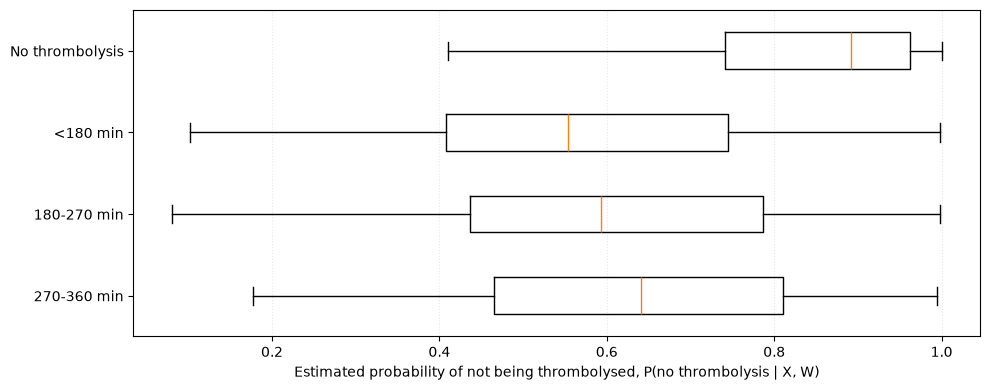

In [9]:
p_none = dr["p0"]
overlap = pd.DataFrame([
    {"treatment_group": g, "n": int(mask.sum()),
     "median P(no thrombolysis)": np.median(p_none[mask]),
     "% with P(no thrombolysis) < 0.05": 100 * (p_none[mask] < 0.05).mean(),
     "% with P(no thrombolysis) < 0.01": 100 * (p_none[mask] < 0.01).mean()}
    for g in [CONTROL_GROUP] + GROUP_ORDER
    for mask in [dr["group"] == g]
]).round(3)
display(overlap)

fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot([p_none[dr["group"] == g] for g in [CONTROL_GROUP] + GROUP_ORDER], vert=False, showfliers=False)
ax.set_yticklabels([CONTROL_GROUP] + GROUP_ORDER)
ax.invert_yaxis()
ax.set_xlabel("Estimated probability of not being thrombolysed, P(no thrombolysis | X, W)")
ax.grid(axis="x", alpha=0.3, linestyle=":")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/{prefix}_overlap.png", dpi=300)
plt.show()

**Observations:**
* Overlap for the main estimand (ATT) is good. Treated patients have a median probability of *not* being thrombolysed of 0.55–0.64, and **none** has a probability below 0.05. Every treated patient therefore has comparable untreated patients.
* As a result, the "Exclude P(no thrombolysis) < 0.05" sensitivity analysis excludes nobody and gives identical results to the primary analysis.
* Overlap is much worse in the other direction (needed for the ATE). Many untreated patients have very low probabilities of thrombolysis in a given window, especially at 270–360 min (see the next table).

## Treatment effects

* **ATT** (main result): the AIPW effect in the patients who were thrombolysed, for each window and for all windows combined.
* **ATE:** the effect if everyone in the cohort were thrombolysed in that window. It is only reported where fewer than 20% of patients have a predicted probability below 0.01.
* **Mean CATE in treated:** the simple average of the forest's individual estimates (no CI, because they share the same trees).

Effects are differences in the probability of a good outcome, in percentage points.

In [10]:
effects = dr_effects(est, X, y, arm, data["stroke_severity"])
effects.to_csv(f"{OUTPUT_DIR}/{prefix}_effects.csv", index=False)

overall = effects[effects["nihss"] == "1-5"].set_index("treatment_group")
effects_table = pd.DataFrame({
    "n treated": overall["n_treated"],
    "ATT, % points (95% CI)": [fmt_pp(*r) for r in overall[["att", "att_ci_lower", "att_ci_upper"]].to_numpy()],
    "ATE, % points (95% CI)": [fmt_pp(*aipw_ate(dr, g)) if g in GROUP_ORDER else "-" for g in overall.index],
    "% of cohort with P(window) < 0.01": [round(100 * (dr["p"][g] < PROPENSITY_CLIP).mean(), 1)
                                          if g in GROUP_ORDER else np.nan for g in overall.index],
    "Mean CATE in treated, % points": (100 * overall["mean_cate"]).round(1),
})
effects_table.to_csv(f"{OUTPUT_DIR}/{prefix}_effects_table.csv")

# Per-patient CATE for each patient's own window (vs no thrombolysis)
cate_df = data[X_FEATURES + ["treatment_group", "outcome_target"]].copy()
cate_df["cate"] = dr["own_theta"]
cate_df.to_csv(f"{OUTPUT_DIR}/{prefix}_causal_forest_cate_estimates.csv", index=True)
effects_table

,n treated,"ATT, % points (95% CI)","ATE, % points (95% CI)",% of cohort with P(window) < 0.01,"Mean CATE in treated, % points"
treatment_group,,,,,
All (≤360 min),13380,"5.0 (4.0, 6.0)",-,NaN,5.0
<180 min,7390,"6.3 (5.1, 7.6)","4.1 (2.3, 5.8)",14.4,6.4
180-270 min,5514,"3.5 (2.1, 4.8)","2.1 (0.1, 4.1)",13.6,3.5
270-360 min,476,"1.8 (-2.1, 5.6)",-,77.2,2.1


**Observations:**
* **ATT:** Thrombolysis increased good outcome by 5.0 points (4.0 to 6.0) in treated patients.
  * The effect was largest when given within 180 min: 6.3 (5.1 to 7.6).
  * It was about half that at 180–270 min: 3.5 (2.1 to 4.8).
  * At 270–360 min, the estimate (1.8, −2.1 to 5.6) is based on only 476 patients and cannot exclude no effect.
* **ATE:** The ATE is smaller than the ATT: 4.1 vs 6.3 within 180 min, and 2.1 vs 3.5 at 180–270 min.
  * Thrombolysis would therefore help the average mild-stroke patient less than it helped those who received it. This fits with clinicians mainly treating patients with higher NIHSS, who benefit most (see the NIHSS section).
  * The ATE is not reported for 270–360 min because 77% of the cohort had a predicted probability below 0.01 of treatment in that window.
* **Mean CATE vs AIPW:** The forest's mean CATE in treated patients (5.0, 6.4, 3.5, 2.1) is very close to the doubly robust ATT, so the forest and the AIPW correction agree.

### Comparison with EconML's built-in doubly robust estimates

EconML's `att__inference` divides by unclipped treatment probabilities. It is shown here for comparison with the AIPW ATT used in this notebook, together with the smallest predicted probability of each patient's own treatment window.

In [11]:
builtin = []
arm_levels = sorted(np.unique(arm))
for k, level in enumerate(arm_levels):
    if level == BASELINE_ARM:
        continue
    group = CODE_TO_GROUP[level]
    builtin.append({
        "treatment_group": group,
        "EconML att__inference, % points": round(100 * float(np.ravel(est.att__inference(T=k).point_estimate)[k - 1]), 1),
        "AIPW ATT (clipped), % points": round(100 * float(overall.loc[group, "att"]), 1),
        "smallest P(own window) in treated": dr["p"][group][dr["group"] == group].min(),
    })
pd.DataFrame(builtin)

,treatment_group,"EconML att__inference, % points","AIPW ATT (clipped), % points",smallest P(own window) in treated
0,<180 min,1.5,6.3,0.000710
1,180-270 min,-2.1,3.5,0.000567
2,270-360 min,-123.8,1.8,0.000075


**Observations:**
* EconML's built-in ATT estimates are implausible: 1.5, −2.1 and **−123.8** percentage points.
* This is because a few treated patients have extremely small estimated probabilities of the window they were actually treated in (as low as 0.00008 at 270–360 min). Dividing by these unclipped probabilities gives single patients huge weights.
* The clipped AIPW ATT used in this notebook is not affected. It agrees with the forest's own mean CATE.

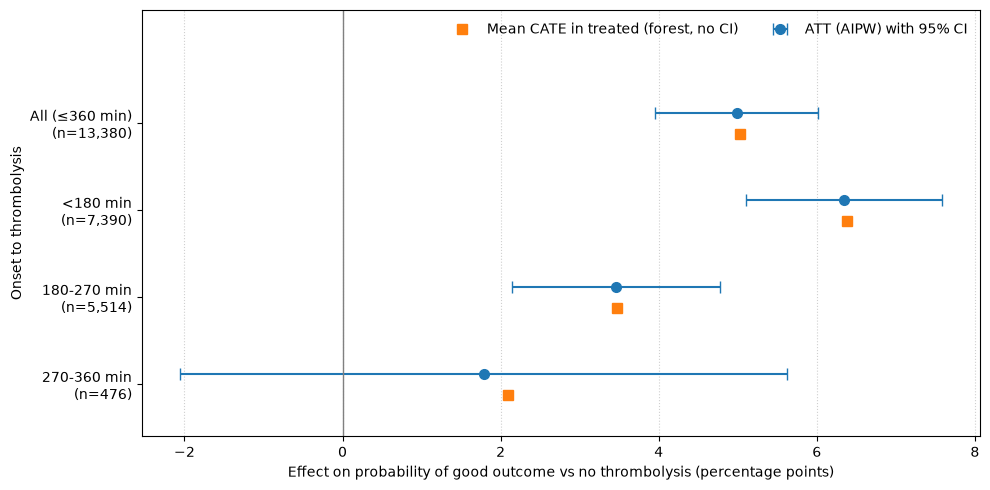

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))
order = [ALL_TREATED] + GROUP_ORDER
ypos = np.arange(len(order))[::-1]
o = overall.reindex(order)
point = 100 * o["att"]
ax.errorbar(point, ypos + 0.12, xerr=[point - 100 * o["att_ci_lower"], 100 * o["att_ci_upper"] - point],
            fmt="o", color="#1f77b4", capsize=4, markersize=7, label="ATT (AIPW) with 95% CI")
ax.plot(100 * o["mean_cate"], ypos - 0.12, "s", color="#ff7f0e", markersize=7, label="Mean CATE in treated (forest, no CI)")
ax.set_yticks(ypos)
ax.set_yticklabels([f"{g}\n(n={int(n):,})" for g, n in zip(order, o["n_treated"])])
ax.axvline(0, color="0.5", lw=1)
ax.set_xlabel("Effect on probability of good outcome vs no thrombolysis (percentage points)")
ax.set_ylabel("Onset to thrombolysis")
ax.grid(axis="x", linestyle=":", alpha=0.6)
ax.set_ylim(-0.6, len(order) + 0.3)  # leave space for the legend above the top row
ax.legend(loc="upper right", frameon=False, ncol=2)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/{prefix}_cate.png", dpi=300)
plt.show()

## Effects by NIHSS score

Doubly robust ATT within each NIHSS score, for each treatment window and all windows combined. The untreated proportion with a good outcome at each NIHSS score is shown for context.

In [13]:
by_nihss = effects[effects["nihss"] != "1-5"].copy()
untreated_good = (pd.Series(y[dr["group"] == CONTROL_GROUP])
                  .groupby(data["stroke_severity"].to_numpy()[dr["group"] == CONTROL_GROUP]).mean())
by_nihss["untreated_good_outcome"] = by_nihss["nihss"].astype(int).map(untreated_good)
by_nihss.to_csv(f"{OUTPUT_DIR}/{prefix}_cate_by_severity.csv", index=False)

nihss_table = (by_nihss.assign(att_publish=[fmt_pp(*r) for r in by_nihss[["att", "att_ci_lower", "att_ci_upper"]].to_numpy()])
               .pivot(index="nihss", columns="treatment_group", values="att_publish")
               .reindex(columns=[ALL_TREATED] + GROUP_ORDER))
nihss_table["Untreated good outcome (%)"] = (100 * untreated_good).round(1).to_numpy()
nihss_table  # ATT, percentage points (95% CI)

treatment_group,All (≤360 min),<180 min,180-270 min,270-360 min,Untreated good outcome (%)
nihss,,,,,
1,"-2.1 (-4.8, 0.7)","-1.0 (-4.6, 2.7)","-2.6 (-6.5, 1.4)","-9.1 (-23.9, 5.7)",83.1
2,"0.2 (-1.7, 2.2)","0.5 (-2.1, 3.0)","0.4 (-2.3, 3.1)","-3.6 (-11.5, 4.4)",78.1
3,"5.3 (3.4, 7.2)","5.0 (2.7, 7.4)","5.9 (3.3, 8.4)","2.7 (-5.4, 10.9)",71.5
4,"5.9 (4.0, 7.9)","7.7 (5.4, 10.0)","3.5 (1.0, 6.0)","5.9 (-1.1, 13.0)",65.1
5,"7.1 (4.8, 9.3)","9.2 (6.6, 11.8)","4.3 (1.5, 7.1)","3.6 (-4.8, 11.9)",61.3


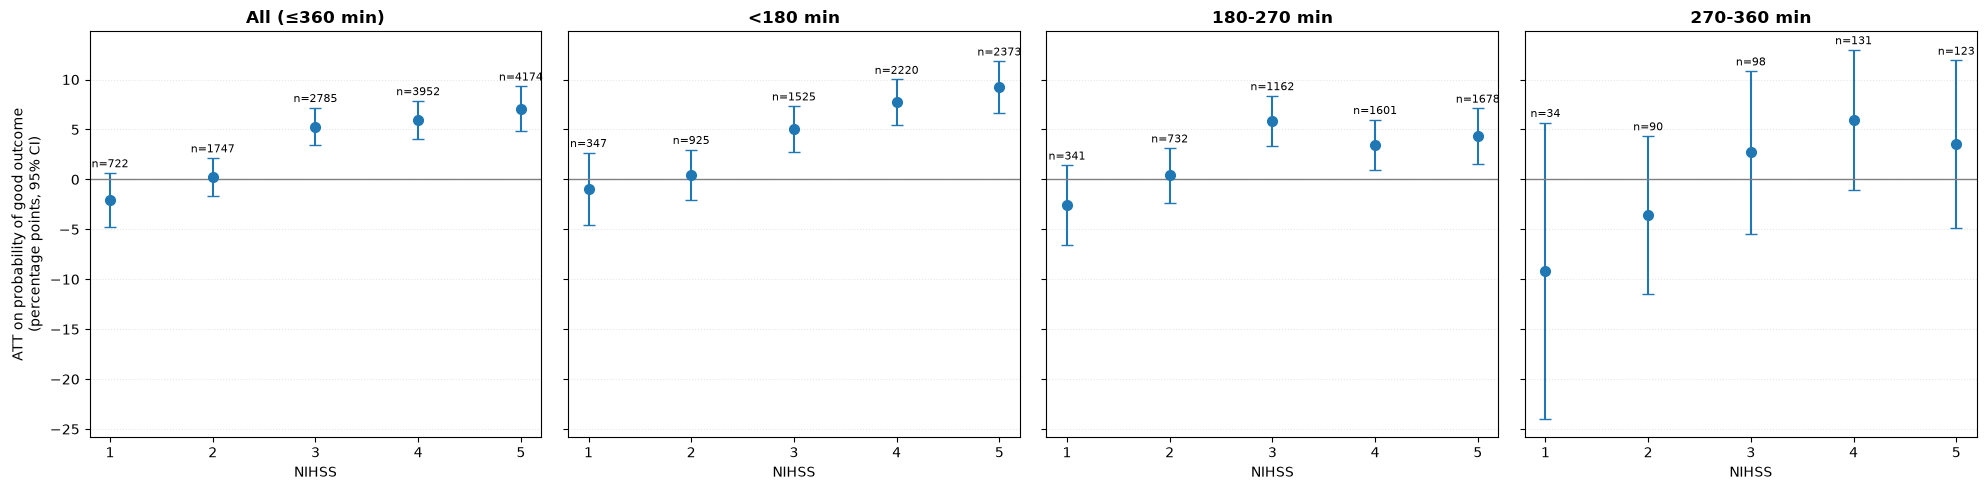

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=True)
for ax, label in zip(axes, [ALL_TREATED] + GROUP_ORDER):
    d = by_nihss[by_nihss["treatment_group"] == label]
    xs = d["nihss"].astype(int).to_numpy()
    point = 100 * d["att"].to_numpy()
    ax.errorbar(xs, point, yerr=[point - 100 * d["att_ci_lower"], 100 * d["att_ci_upper"] - point],
                fmt="o", capsize=4, markersize=7, color="#1f77b4")
    for xi, yi, n in zip(xs, 100 * d["att_ci_upper"], d["n_treated"]):
        ax.annotate(f"n={n}", (xi, yi), textcoords="offset points", xytext=(0, 4), ha="center", fontsize=8)
    ax.axhline(0, color="0.5", lw=1)
    ax.set_title(label, fontweight="bold")
    ax.set_xlabel("NIHSS")
    ax.set_xticks(NIHSS_VALUES)
    ax.grid(axis="y", alpha=0.3, linestyle=":")
axes[0].set_ylabel("ATT on probability of good outcome\n(percentage points, 95% CI)")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/{prefix}_cate_by_severity.png", dpi=300)
plt.show()

**Observations:**
* **Benefit by NIHSS:** The benefit rises steadily with NIHSS (all windows combined):
  * −2.1 (−4.8 to 0.7) at NIHSS 1
  * 0.2 (−1.7 to 2.2) at NIHSS 2
  * 5.3 (3.4 to 7.2) at NIHSS 3
  * 5.9 (4.0 to 7.9) at NIHSS 4
  * 7.1 (4.8 to 9.3) at NIHSS 5
* **No detectable benefit at NIHSS 1–2:** Untreated patients with NIHSS 1–2 have a good outcome 78–83% of the time, leaving little room for improvement. The negative point estimate at NIHSS 1 is not statistically significant.
* **Timing within NIHSS:**
  * Within 180 min, the gradient is steeper: 9.2 points (6.6 to 11.8) at NIHSS 5.
  * At 180–270 min, the benefit at NIHSS 3–5 is 3.5–5.9 points.
  * At 270–360 min, the CIs are too wide to draw conclusions at any NIHSS score.

### Comparison with the matched target trial emulation

The matched target trial emulation (`4_target_trial_emulation/02_...`) estimates the same quantity, the effect in the treated, by exact matching on pre-stroke mRS, NIHSS, age and atrial fibrillation. Its CIs come from paired differences. Agreement between the two methods makes the results more credible.

,NIHSS,Onset to thrombolysis,Causal forest ATT (95% CI),Matched TTE (95% CI),Difference (CF - TTE)
1,1,All (≤360 min),"-2.1 (-4.8, 0.7)","-0.3 (-4.0, 3.5)",-1.8
2,2,All (≤360 min),"0.2 (-1.7, 2.2)","0.9 (-1.6, 3.3)",-0.6
3,3,All (≤360 min),"5.3 (3.4, 7.2)","4.8 (2.7, 6.9)",0.5
4,4,All (≤360 min),"5.9 (4.0, 7.9)","6.6 (4.7, 8.5)",-0.6
5,5,All (≤360 min),"7.1 (4.8, 9.3)","8.5 (6.6, 10.5)",-1.4
0,1-5,All (≤360 min),"5.0 (4.0, 6.0)","5.7 (4.7, 6.7)",-0.7


,NIHSS,Onset to thrombolysis,Causal forest ATT (95% CI),Matched TTE (95% CI),Difference (CF - TTE)
0,1-5,All (≤360 min),"5.0 (4.0, 6.0)","5.7 (4.7, 6.7)",-0.7
6,1-5,<180 min,"6.3 (5.1, 7.6)","6.8 (5.4, 8.1)",-0.4
12,1-5,180-270 min,"3.5 (2.1, 4.8)","4.6 (3.0, 6.2)",-1.1
18,1-5,270-360 min,"1.8 (-2.1, 5.6)","2.1 (-3.1, 7.3)",-0.3


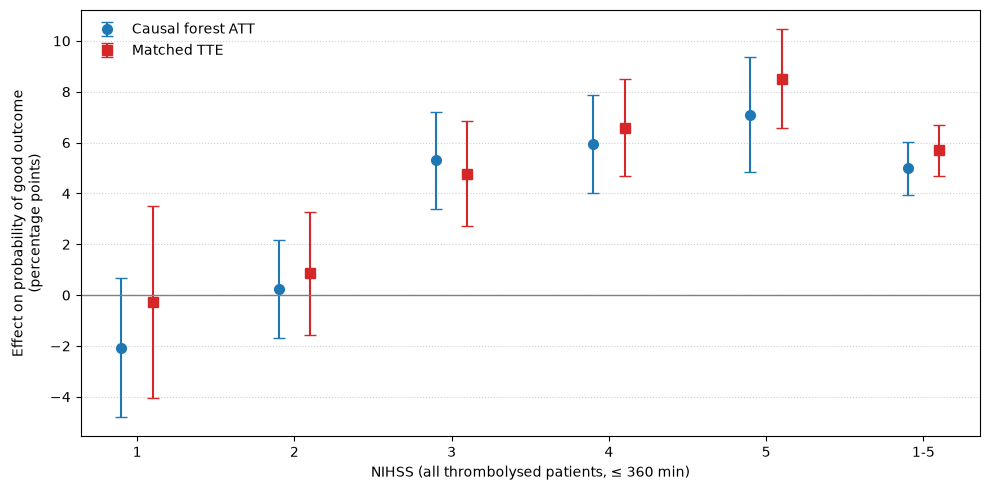

In [15]:
try:
    tte = pd.read_csv(TTE_SUMMARY_PATH, dtype={"nihss": str})
    comparison = effects.merge(
        tte[["nihss", "treatment_group", "difference", "difference_ci_lower", "difference_ci_upper"]],
        on=["nihss", "treatment_group"])
    comparison_table = pd.DataFrame({
        "NIHSS": comparison["nihss"],
        "Onset to thrombolysis": comparison["treatment_group"],
        "Causal forest ATT (95% CI)": [fmt_pp(*r) for r in comparison[["att", "att_ci_lower", "att_ci_upper"]].to_numpy()],
        "Matched TTE (95% CI)": [fmt_pp(*r) for r in comparison[["difference", "difference_ci_lower", "difference_ci_upper"]].to_numpy()],
        "Difference (CF - TTE)": (100 * (comparison["att"] - comparison["difference"])).round(1),
    })
    display(comparison_table[comparison_table["Onset to thrombolysis"] == ALL_TREATED]
            .sort_values("NIHSS", key=lambda s: s.map({k: i for i, k in enumerate(NIHSS_LABELS[1:] + ["1-5"])})))
    display(comparison_table[comparison_table["NIHSS"] == "1-5"])

    fig, ax = plt.subplots(figsize=(10, 5))
    c = comparison[comparison["treatment_group"] == ALL_TREATED].set_index("nihss").reindex(NIHSS_LABELS[1:] + ["1-5"])
    xs = np.arange(len(c))
    for offset, cols, label, colour, marker in [
            (-0.1, ("att", "att_ci_lower", "att_ci_upper"), "Causal forest ATT", "#1f77b4", "o"),
            (0.1, ("difference", "difference_ci_lower", "difference_ci_upper"), "Matched TTE", "#d62728", "s")]:
        point = 100 * c[cols[0]]
        ax.errorbar(xs + offset, point, yerr=[point - 100 * c[cols[1]], 100 * c[cols[2]] - point],
                    fmt=marker, color=colour, capsize=4, markersize=7, label=label)
    ax.set_xticks(xs)
    ax.set_xticklabels(c.index)
    ax.set_xlabel("NIHSS (all thrombolysed patients, ≤ 360 min)")
    ax.set_ylabel("Effect on probability of good outcome\n(percentage points)")
    ax.axhline(0, color="0.5", lw=1)
    ax.grid(axis="y", linestyle=":", alpha=0.6)
    ax.legend(frameon=False)
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/{prefix}_vs_target_trial.png", dpi=300)
    plt.show()
except FileNotFoundError:
    print(f"Target trial emulation results not found at {TTE_SUMMARY_PATH}; run that notebook first.")

**Observations:**
* The two methods agree closely, and every causal forest CI overlaps the TTE CI:
  * By NIHSS, the differences (causal forest − TTE) are −1.8, −0.6, +0.5, −0.6 and −1.4 points.
  * Overall: 5.0 vs 5.7.
  * By window: 6.3 vs 6.8 (<180 min), 3.5 vs 4.6 (180–270 min) and 1.8 vs 2.1 (270–360 min).
* Both methods show the same pattern: no benefit at NIHSS 1–2, clear benefit at NIHSS 3–5, and a smaller benefit with later treatment.
* The causal forest is slightly lower in most comparisons. It adjusts for more characteristics than the exact matching (including stroke team, comorbidities and ethnicity), which may remove a small amount of residual confounding.
* The methods differ in their modelling assumptions but share the same assumption of no unmeasured confounding. Their agreement shows robustness to how measured confounders are handled, not to unmeasured confounding.

## Effects in subgroups of patients treated within 270 minutes

For patients thrombolysed within 270 minutes (< 180 and 180–270 min combined), the doubly robust ATT is estimated within each level of each patient characteristic. Subgroups with fewer than `MIN_SUBGROUP_TREATED` (30) treated patients are not shown.

Whether the effect differs between levels of a characteristic is tested with a chi-square test of homogeneity. For K levels, Q = Σ wₖ (ATTₖ − weighted mean)² with wₖ = 1 / SEₖ², compared with a χ² distribution on K − 1 degrees of freedom. P values are not adjusted for multiple comparisons.

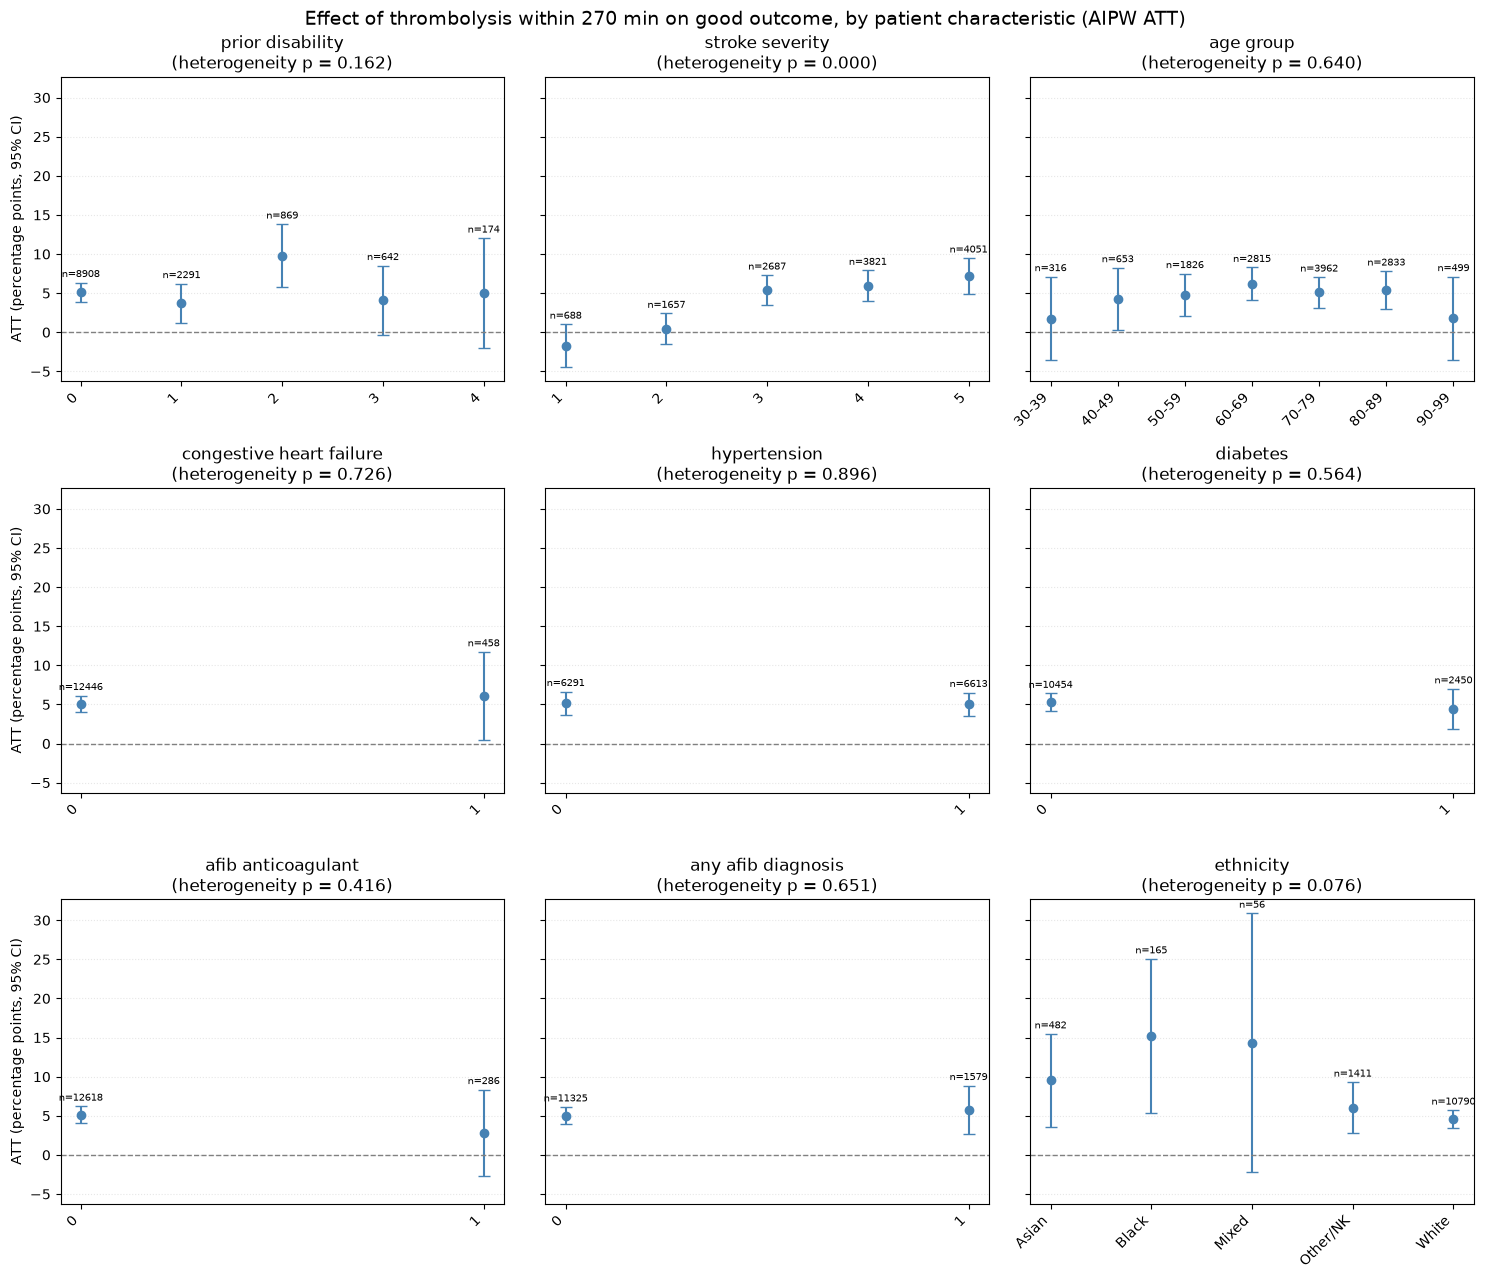

,feature,levels,Q,df,p_value
0,prior_disability,5,6.551,4,0.162
1,stroke_severity,5,42.594,4,0.000
2,age_group,7,4.271,6,0.640
3,congestive_heart_failure,2,0.122,1,0.726
4,hypertension,2,0.017,1,0.896
5,diabetes,2,0.333,1,0.564
6,afib_anticoagulant,2,0.660,1,0.416
7,any_afib_diagnosis,2,0.204,1,0.651
8,ethnicity,5,8.468,4,0.076


In [16]:
UNDER_270 = ["<180 min", "180-270 min"]
data["age_group"] = pd.cut(data["age"], bins=np.arange(0, 110, 10), right=False)
SUBGROUP_FEATURES = ["prior_disability", "stroke_severity", "age_group", "congestive_heart_failure",
                     "hypertension", "diabetes", "afib_anticoagulant", "any_afib_diagnosis", "ethnicity"]

subgroup_rows, homogeneity = [], []
for feature in SUBGROUP_FEATURES:
    values = data[feature].to_numpy()
    levels = sorted(pd.Series(values).dropna().unique(), key=lambda v: v.left if isinstance(v, pd.Interval) else v)
    atts, ses = [], []
    for level in levels:
        att, lo, hi, n_treated = aipw_att(dr, UNDER_270, subgroup=(values == level))
        if n_treated < MIN_SUBGROUP_TREATED or np.isnan(att):
            continue
        label = f"{int(level.left)}-{int(level.right) - 1}" if isinstance(level, pd.Interval) else (
            str(int(level)) if isinstance(level, (int, float, np.integer, np.floating)) and float(level).is_integer() else str(level))
        subgroup_rows.append({"feature": feature, "level": label, "n_treated": n_treated,
                              "att": att, "att_ci_lower": lo, "att_ci_upper": hi})
        atts.append(att)
        ses.append((hi - lo) / (2 * 1.96))
    if len(atts) > 1:
        w = 1 / np.square(ses)
        q = float(np.sum(w * np.square(np.array(atts) - np.sum(w * atts) / np.sum(w))))
        homogeneity.append({"feature": feature, "levels": len(atts), "Q": q, "df": len(atts) - 1,
                            "p_value": stats.chi2.sf(q, len(atts) - 1)})
subgroups = pd.DataFrame(subgroup_rows)
subgroups.to_csv(f"{OUTPUT_DIR}/{prefix}_subgroup_att_treated_under_270_min.csv", index=False)
homogeneity = pd.DataFrame(homogeneity)
homogeneity.to_csv(f"{OUTPUT_DIR}/{prefix}_subgroup_homogeneity_tests.csv", index=False)

fig, axes = plt.subplots(3, 3, figsize=(15, 13), sharey=True)
for ax, feature in zip(axes.flat, SUBGROUP_FEATURES):
    d = subgroups[subgroups["feature"] == feature]
    xs = np.arange(len(d))
    point = 100 * d["att"].to_numpy()
    ax.errorbar(xs, point, yerr=[point - 100 * d["att_ci_lower"], 100 * d["att_ci_upper"] - point],
                fmt="o", capsize=4, markersize=6, color="steelblue")
    for xi, yi, n in zip(xs, 100 * d["att_ci_upper"], d["n_treated"]):
        ax.annotate(f"n={n}", (xi, yi), textcoords="offset points", xytext=(0, 4), ha="center", fontsize=7)
    p = homogeneity.loc[homogeneity["feature"] == feature, "p_value"]
    ax.set_title(f"{feature.replace('_', ' ')}" + (f"\n(heterogeneity p = {p.iloc[0]:.3f})" if len(p) else ""))
    ax.set_xticks(xs)
    ax.set_xticklabels(d["level"], rotation=45, ha="right")
    ax.axhline(0, color="0.5", lw=1, linestyle="--")
    ax.grid(axis="y", alpha=0.3, linestyle=":")
for ax in axes[:, 0]:
    ax.set_ylabel("ATT (percentage points, 95% CI)")
fig.suptitle(f"Effect of thrombolysis within 270 min on good outcome, by patient characteristic (AIPW ATT)", fontsize=14)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/{prefix}_subgroup_att_treated_under_270_min.png", dpi=300, bbox_inches="tight")
plt.show()
homogeneity.round(3)

**Observations (patients treated within 270 min):**
* **Stroke severity** is the only characteristic with clear evidence that the effect varies (p < 0.001): −1.7, 0.4, 5.4, 6.0 and 7.2 points for NIHSS 1–5.
* **Ethnicity** shows weak evidence of variation (p = 0.076):
  * Larger point estimates in Asian (9.5, n = 482), Black (15.2, n = 165) and Mixed (14.4, n = 56) patients than in White patients (4.6).
  * These groups are small, the CIs are wide, and the p value is not adjusted for multiple testing. This should be treated as hypothesis-generating only.
* **No evidence of variation** by pre-stroke disability (p = 0.16), age (p = 0.64), heart failure, hypertension, diabetes or atrial fibrillation (all p > 0.4).
  * The benefit is similar from age 40 to 89 (4.3–6.2 points).
  * There is a benefit in patients with pre-stroke disability (mRS 1–2: 3.7 and 9.8 points).

## Sensitivity analyses

Each analysis refits the whole model with **one** change. It reports the AIPW ATT for each window, all windows combined, and each NIHSS score (all windows combined).

| Category | Analysis | Why |
|---|---|---|
| Model specification | Original (incorrect) categorical indices | Shows how much the categorical-feature fix changes the results. |
| Confounders | Without stroke team | Tests how much adjustment for hospital practice matters. |
| Confounders | Also adjust for onset-to-scan time and year | Both were adjusted for in the non-mild analysis. Onset-to-scan time strongly predicts how soon thrombolysis can be given. |
| Overlap | Exclude patients with P(no thrombolysis) < 0.05 | Removes patients with no comparable untreated patients. |
| First stage | Smaller LightGBM models (200 trees, 15 leaves) | Tests sensitivity to first-stage model complexity. |
| Forest | Minimum leaf size 50 | Tests sensitivity to forest settings. |
| Cross-fitting | Folds grouped by stroke team | Each team's patients are predicted by models trained on other teams. |
| Cohort | Arrival within 180 min | Patients arriving later in the 4-hour window have less time to be treated. |
| Cohort | All teams / teams with at least 20 thrombolyses | Tests the team thrombolysis-volume restriction (at least 10). |
| Outcome | mRS 0–2 only; mRS 0–1 only; mRS 0–1 or no worse than pre-stroke | mRS 0–1 (excellent outcome) is the usual outcome in trials of mild stroke. |
| Random seed | 3 other seeds | Variation from random cross-fitting splits, subsampling and the forest. |

Each refit takes about as long as the primary fit (printed above). Results are saved to CSV as they are produced.

In [ ]:
# Original categorical indices: X-relative for the outcome model, W-relative for the treatment model
X_tmp, W_tmp, *_ = build_matrices(data)
original_cat_idx_y = [X_tmp.columns.get_loc(c) for c in CATEGORICAL_FEATURES if c in X_tmp.columns]
original_cat_idx_t = [W_tmp.columns.get_loc(c) for c in ["stroke_team", "ethnicity"]]

trimmed = data[dr["p0"] >= 0.05].copy()
trimmed["patient_id"] = np.arange(len(trimmed))
scan_year_cohort = build_cohort(raw_data, extra_features=["onset_to_scan_time", "year"])

# (analysis, category, cohort, keyword arguments for fit_causal_forest)
SCENARIOS = [
    ("Original categorical indices", "Model specification", data,
     {"cat_idx_y": original_cat_idx_y, "cat_idx_t": original_cat_idx_t}),
    ("Without stroke team", "Confounders", data, {"w_features": X_FEATURES}),
    ("Also adjust for onset-to-scan time and year", "Confounders", scan_year_cohort,
     {"w_features": W_FEATURES + ["onset_to_scan_time", "year"]}),
    ("Exclude P(no thrombolysis) < 0.05", "Overlap", trimmed, {}),
    ("Smaller LightGBM (200 trees, 15 leaves)", "First stage", data,
     {"nuisance_params": dict(NUISANCE_PARAMS, n_estimators=200, num_leaves=15)}),
    ("Minimum leaf size 50", "Forest", data, {"min_samples_leaf": 50}),
    ("Folds grouped by stroke team", "Cross-fitting", data, {"groups": "team"}),
    ("Arrival within 180 min", "Cohort", build_cohort(raw_data, max_arrival=180), {}),
    ("All teams (no thrombolysis-volume limit)", "Cohort", build_cohort(raw_data, min_team_thrombolysis=0), {}),
    ("Teams with at least 20 thrombolyses", "Cohort", build_cohort(raw_data, min_team_thrombolysis=20), {}),
    ("Outcome: mRS 0-2 only", "Outcome definition", data, {"allow_no_worse_than_prior": False}),
    ("Outcome: mRS 0-1 only", "Outcome definition", data, {"mrs_target": 1, "allow_no_worse_than_prior": False}),
    ("Outcome: mRS 0-1 or no worse than pre-stroke", "Outcome definition", data, {"mrs_target": 1}),
    ("Seed 1", "Random seed", data, {"seed": 1}),
    ("Seed 2", "Random seed", data, {"seed": 2}),
    ("Seed 3", "Random seed", data, {"seed": 3}),
]

sensitivity_results = [effects]
for analysis, category, cohort, kwargs in SCENARIOS:
    est_s, X_s, _, y_s, arm_s, seconds = fit_causal_forest(cohort, **kwargs)
    sensitivity_results.append(dr_effects(est_s, X_s, y_s, arm_s, cohort["stroke_severity"], analysis, category))
    print(f"{analysis}: {seconds / 60:.1f} min")
    if analysis == "Original categorical indices":
        # Check: plug-in mean CATE should reproduce the earlier notebook (0.0645 for < 180 min)
        mask = (cohort["treatment_group"] == "<180 min").to_numpy()
        print("  Earlier version reproduced? mean CATE, < 180 min:",
              round(float(est_s.effect(X_s.loc[mask].to_numpy(), T0=BASELINE_ARM, T1=ARM_CODES["<180 min"]).mean()), 4))
    pd.concat(sensitivity_results).to_csv(f"{OUTPUT_DIR}/{prefix}_sensitivity.csv", index=False)

sensitivity_df = pd.concat(sensitivity_results, ignore_index=True)
sensitivity_df.to_csv(f"{OUTPUT_DIR}/{prefix}_sensitivity.csv", index=False)

Original categorical indices: 1.9 min
  Earlier version reproduced? mean CATE, < 180 min: 0.0645
Without stroke team: 2.2 min
Also adjust for onset-to-scan time and year: 3.6 min
Exclude P(no thrombolysis) < 0.05: 1.7 min
Smaller LightGBM (200 trees, 15 leaves): 1.3 min
Minimum leaf size 50: 2.5 min
Folds grouped by stroke team: 2.8 min


In [ ]:
# Columns: each window and all combined (NIHSS 1-5), then each NIHSS score (all windows combined)
sens = sensitivity_df.copy()
sens["column"] = np.where(sens["nihss"] == "1-5", sens["treatment_group"], "NIHSS " + sens["nihss"])
sens = sens[(sens["nihss"] == "1-5") | (sens["treatment_group"] == ALL_TREATED)]
sens["att_publish"] = [fmt_pp(*r) for r in sens[["att", "att_ci_lower", "att_ci_upper"]].to_numpy()]
analysis_order = list(dict.fromkeys(sens["analysis"]))
column_order = [ALL_TREATED] + GROUP_ORDER + [f"NIHSS {n}" for n in NIHSS_VALUES]
sensitivity_table = sens.pivot(index="analysis", columns="column", values="att_publish").reindex(
    index=analysis_order, columns=column_order)
sensitivity_table.to_csv(f"{OUTPUT_DIR}/{prefix}_sensitivity_table.csv")
sensitivity_table  # ATT, percentage points (95% CI)

column,All (≤360 min),<180 min,180-270 min,270-360 min,NIHSS 1,NIHSS 2,NIHSS 3,NIHSS 4,NIHSS 5
analysis,,,,,,,,,
Primary,"5.0 (4.0, 6.0)","6.3 (5.1, 7.6)","3.5 (2.1, 4.8)","1.8 (-2.1, 5.6)","-2.1 (-4.8, 0.7)","0.2 (-1.7, 2.2)","5.3 (3.4, 7.2)","5.9 (4.0, 7.9)","7.1 (4.8, 9.3)"
Original categorical indices,"5.1 (4.1, 6.1)","6.5 (5.4, 7.7)","3.5 (2.2, 4.7)","1.9 (-1.9, 5.7)","-2.1 (-4.8, 0.6)","0.4 (-1.5, 2.2)","5.3 (3.5, 7.1)","6.1 (4.3, 7.9)","7.3 (5.2, 9.4)"
Without stroke team,"5.1 (4.1, 6.1)","6.3 (5.1, 7.4)","3.7 (2.4, 5.0)","3.2 (-0.6, 7.1)","-1.8 (-4.5, 1.0)","0.8 (-1.0, 2.7)","5.0 (3.3, 6.7)","6.0 (4.2, 7.8)","7.3 (5.2, 9.4)"
Also adjust for onset-to-scan time and year,"3.4 (2.3, 4.6)","3.7 (2.1, 5.2)","3.3 (1.8, 4.9)","0.9 (-3.2, 4.9)","-2.4 (-5.2, 0.4)","-1.0 (-3.0, 1.0)","4.3 (2.3, 6.3)","4.3 (2.1, 6.4)","4.9 (2.3, 7.5)"
Exclude P(no thrombolysis) < 0.05,"5.0 (4.0, 6.0)","6.3 (5.1, 7.6)","3.5 (2.1, 4.8)","1.8 (-2.1, 5.6)","-2.1 (-4.8, 0.7)","0.2 (-1.7, 2.2)","5.3 (3.4, 7.2)","5.9 (4.0, 7.9)","7.1 (4.8, 9.3)"
"Smaller LightGBM (200 trees, 15 leaves)","5.1 (4.1, 6.1)","6.6 (5.4, 7.7)","3.5 (2.2, 4.8)","1.9 (-1.9, 5.7)","-1.9 (-4.6, 0.9)","0.4 (-1.4, 2.3)","5.3 (3.5, 7.1)","6.2 (4.3, 8.0)","7.2 (5.1, 9.4)"
Minimum leaf size 50,"5.0 (4.0, 6.0)","6.3 (5.1, 7.6)","3.5 (2.2, 4.8)","1.7 (-2.1, 5.6)","-2.1 (-4.8, 0.7)","0.2 (-1.7, 2.2)","5.3 (3.4, 7.2)","5.9 (4.0, 7.9)","7.1 (4.8, 9.4)"
Folds grouped by stroke team,"5.3 (4.3, 6.2)","6.1 (5.0, 7.2)","4.2 (2.9, 5.5)","5.0 (1.1, 8.8)","-1.7 (-4.4, 1.0)","0.9 (-0.9, 2.7)","5.1 (3.5, 6.8)","6.5 (4.7, 8.4)","7.2 (5.2, 9.1)"
Arrival within 180 min,"5.4 (4.2, 6.5)","6.3 (5.0, 7.6)","3.8 (2.3, 5.3)","5.5 (-0.4, 11.4)","-2.0 (-4.9, 0.8)","-0.4 (-2.5, 1.8)","5.2 (3.2, 7.2)","7.0 (4.8, 9.2)","7.7 (5.1, 10.3)"


**Observations:**
* **Very stable:**
  * Random seeds: the overall effect was 5.0–5.1 and <180 min was 6.4–6.6.
  * Forest leaf size and smaller first-stage models.
  * The original categorical indices: 5.1, and its mean CATE reproduced the earlier version of this notebook (0.0645).
  * Removing stroke team: 5.1.
  * Team-grouped cross-fitting: 5.3.
  * Restricting arrival to 180 min: 5.4.
  * Changing the team thrombolysis-volume limit: 5.0–5.1.
  * Overlap trimming: identical, because no patients were removed.
* **Late window (270–360 min):** This window is fragile. Estimates ranged from 0.8 to 5.5, and one analysis had a CI excluding zero (grouped folds: 5.0, 1.1 to 8.8). This reflects the small number of patients (n = 476).
* **Onset-to-scan time and year:** Adding these to the adjustment set had the largest effect. The overall estimate fell from 5.0 to 3.4 (2.3 to 4.6); <180 min fell from 6.3 to 3.7; NIHSS 5 fell from 7.1 to 4.9. The 180–270 min estimate was unchanged.
  * Onset-to-scan time is measured before treatment and determines which windows are possible. Untreated patients with fast scans may often have been deliberately not treated, for example because of rapidly improving symptoms, which predicts a good outcome.
  * Adjusting for it may therefore remove confounding or introduce bias. The primary analysis and this analysis can be seen as plausible bounds. Both still show a clear benefit.
* **Outcome definition:** With an excellent outcome (mRS 0–1), the effect was larger: 6.2 overall and 7.5 within 180 min.
  * The NIHSS 1 estimate moved from −2.1 to +0.4.
  * NIHSS 2 rose to 2.0 (−0.4 to 4.5).
  * NIHSS 4 rose to 8.6.
  * In mild stroke, thrombolysis mainly moves patients from mRS 2 to mRS 0–1. The usual trial outcome (mRS 0–1) shows more benefit than mRS 0–2.
* **NIHSS 1:** The estimate is negative (−1.7 to −2.4) in every analysis using mRS 0–2, but its CI always includes zero.

### Forest plot of sensitivity analyses

One panel per estimate: each window and all windows combined (NIHSS 1–5), and each NIHSS score (all windows combined). Points are the AIPW ATT with 95% CI; the dashed line is the primary estimate.

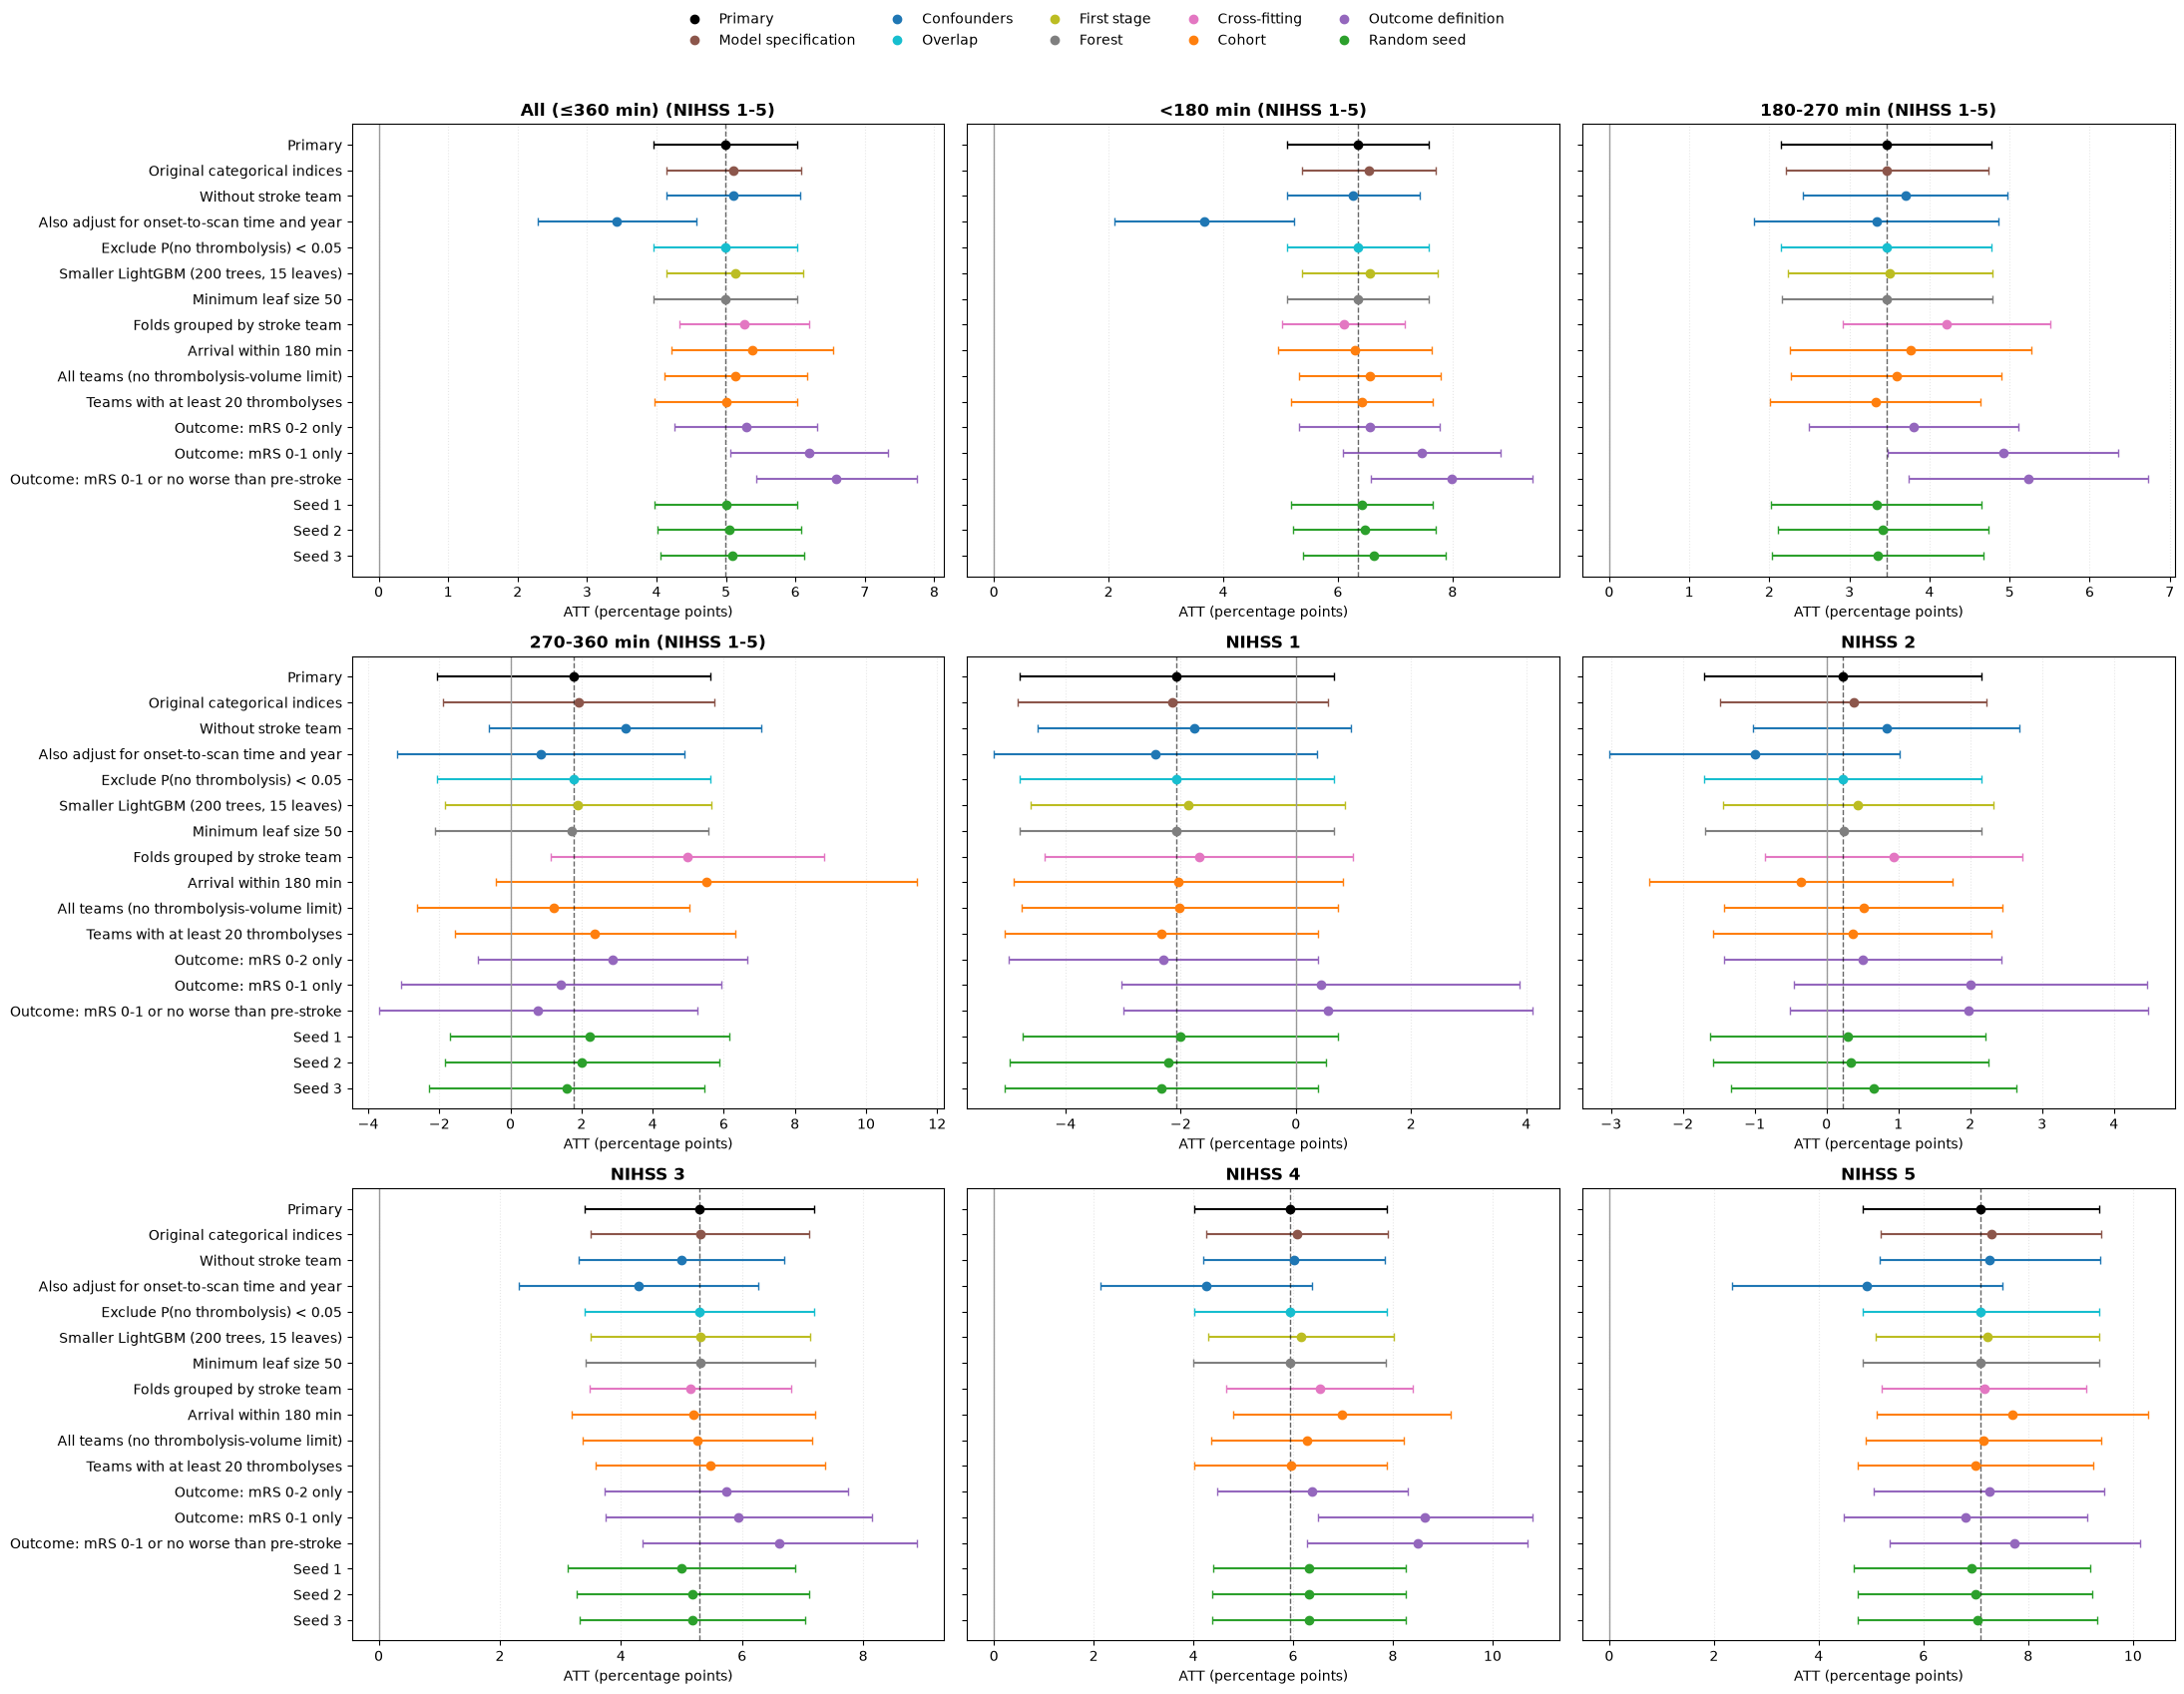

In [ ]:
category_colours = {
    "Primary": "black", "Model specification": "#8c564b", "Confounders": "#1f77b4", "Overlap": "#17becf",
    "First stage": "#bcbd22", "Forest": "#7f7f7f", "Cross-fitting": "#e377c2",
    "Cohort": "#ff7f0e", "Outcome definition": "#9467bd", "Random seed": "#2ca02c",
}
fig, axes = plt.subplots(3, 3, figsize=(22, 17), sharey=True)
y_pos = {a: i for i, a in enumerate(analysis_order[::-1])}
for ax, column in zip(axes.flat, column_order):
    df = sens[sens["column"] == column]
    for _, r in df.iterrows():
        colour = category_colours[r["category"]]
        ax.errorbar(100 * r["att"], y_pos[r["analysis"]],
                    xerr=[[100 * (r["att"] - r["att_ci_lower"])], [100 * (r["att_ci_upper"] - r["att"])]],
                    fmt="o", color=colour, ecolor=colour, capsize=3, markersize=6)
    ax.axvline(100 * df.loc[df["analysis"] == "Primary", "att"].iloc[0], color="black", linestyle="--", lw=1, alpha=0.6)
    ax.axvline(0, color="0.6", lw=1)
    ax.set_title(column if column.startswith("NIHSS") else f"{column} (NIHSS 1-5)", fontweight="bold")
    ax.set_xlabel("ATT (percentage points)")
    ax.grid(axis="x", alpha=0.3, linestyle=":")
for ax in axes.flat[len(column_order):]:
    ax.axis("off")
axes[0, 0].set_yticks(list(y_pos.values()))
axes[0, 0].set_yticklabels(list(y_pos.keys()))
for ax in axes[:, 0]:
    ax.tick_params(labelleft=True)
handles = [plt.Line2D([], [], marker="o", color=c, linestyle="", label=k) for k, c in category_colours.items()]
fig.legend(handles=handles, loc="upper center", ncol=5, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(f"{OUTPUT_DIR}/{prefix}_sensitivity.png", dpi=300)
plt.show()

### E-values for unmeasured confounding

The E-value is the minimum strength of association, on the risk-ratio scale, that an unmeasured confounder would need with **both** thrombolysis and good outcome (beyond those adjusted for) to fully explain away the effect (VanderWeele & Ding, *Ann Intern Med* 2017;167:268–274).

The ATT is a risk difference. To turn it into a risk ratio, the treated patients' observed good-outcome proportion (p₁) is compared with their estimated proportion without treatment, p₀ = p₁ − ATT. The same is done for the CI limit closest to no effect. This conversion is approximate.

In [ ]:
def e_value(rr):
    rr = np.asarray(rr, dtype=float)
    rr = np.where(rr < 1, 1 / rr, rr)
    return rr + np.sqrt(rr * (rr - 1))

ev = effects[(effects["nihss"] == "1-5") | (effects["treatment_group"] == ALL_TREATED)].copy()
ev["risk_ratio"] = ev["p_treated"] / (ev["p_treated"] - ev["att"])
closest = np.where(ev["att"] >= 0, ev["att_ci_lower"], ev["att_ci_upper"])
crosses_null = (ev["att_ci_lower"] <= 0) & (ev["att_ci_upper"] >= 0)
ev["e_value"] = e_value(ev["risk_ratio"])
ev["e_value_ci"] = np.where(crosses_null, 1.0, e_value(ev["p_treated"] / (ev["p_treated"] - closest)))
ev = ev[["treatment_group", "nihss", "n_treated", "att", "att_ci_lower", "att_ci_upper",
         "p_treated", "risk_ratio", "e_value", "e_value_ci"]]
ev.to_csv(f"{OUTPUT_DIR}/{prefix}_e_values.csv", index=False)
ev.round(3)

,treatment_group,nihss,n_treated,att,att_ci_lower,att_ci_upper,p_treated,risk_ratio,e_value,e_value_ci
0,All (≤360 min),1-5,13380,0.050,0.040,0.060,0.774,1.069,1.340,1.292
1,All (≤360 min),1,722,-0.021,-0.048,0.007,0.846,0.976,1.183,1.000
2,All (≤360 min),2,1747,0.002,-0.017,0.022,0.837,1.003,1.055,1.000
3,All (≤360 min),3,2785,0.053,0.034,0.072,0.815,1.070,1.342,1.257
4,All (≤360 min),4,3952,0.059,0.040,0.079,0.764,1.084,1.387,1.297
5,All (≤360 min),5,4174,0.071,0.048,0.093,0.718,1.110,1.458,1.350
6,<180 min,1-5,7390,0.063,0.051,0.076,0.787,1.088,1.396,1.342
12,180-270 min,1-5,5514,0.035,0.021,0.048,0.758,1.048,1.272,1.202
18,270-360 min,1-5,476,0.018,-0.021,0.056,0.771,1.024,1.179,1.000


**Observations:**
* **E-values are modest:**
  * 1.34 overall (CI limit 1.29)
  * 1.40 within 180 min (1.34)
  * 1.27 at 180–270 min (1.20)
  * 1.34–1.46 at NIHSS 3–5
* An unmeasured confounder associated with both thrombolysis and good outcome by a risk ratio of about 1.3–1.4, beyond the measured characteristics, could explain away the effect.
* E-values are naturally small here because good outcome is common (77% in treated patients), so a 5-point difference is a risk ratio of only 1.07.
* Plausible unmeasured confounders exist, including:
  * rapidly improving symptoms
  * how disabling the deficit is (not captured by NIHSS)
  * contraindications such as recent surgery or bleeding risk
* These results therefore depend on the assumption of no unmeasured confounding.

## Conclusions and limitations

**Conclusions**
* In patients with mild stroke (NIHSS 1–5) arriving within 4 hours, thrombolysis was associated with a higher probability of a good outcome in those treated: about 5 percentage points overall and about 6 points if given within 180 min.
* The benefit fell with later treatment and was uncertain beyond 270 min.
* The benefit depended strongly on stroke severity:
  * **NIHSS 3–5:** consistent benefit of about 5–7 points (up to 9 points within 180 min).
  * **NIHSS 1–2:** no detectable benefit on mRS 0–2, and at most a small, non-significant benefit on mRS 0–1. This is consistent with randomised evidence in non-disabling minor stroke (e.g. PRISMS, ARAMIS).
* The doubly robust causal forest agrees with the matched target trial emulation to within 2 points. The results are stable across model settings, cohorts, seeds and outcome definitions.

**Limitations**
* **Unmeasured confounding:** The main threat is confounding by factors not in SSNAP, especially rapidly improving or non-disabling symptoms and contraindications. The E-values (about 1.3–1.4) show only modest unmeasured confounding would be needed to explain the results.
* **Onset-to-scan time:** Adjusting for onset-to-scan time and year reduced the overall estimate to 3.4 points. It is unclear whether this variable should be adjusted for.
* **Timing:** Treatment windows are defined by time of treatment, which is only known for treated patients. Untreated patients have no "time zero", so the comparison is with no treatment at any time rather than with delayed treatment.
* **Late window and small subgroups:** The 270–360 min group and the smaller ethnic groups are small, so their estimates are uncertain. Subgroup p values are not adjusted for multiple testing.
* **Outcome:** The outcome is mRS at discharge, not at 90 days. Discharge mRS can differ from longer-term outcome, especially in mild stroke.
* **Overlap for the ATE:** Overlap is limited for the ATE. The ATE is therefore reported only where at least 80% of patients have a predicted probability of 0.01 or more for the treatment window.